# Step 4. Edges: 2000 - 2020 y 2021 - 2022- 2023 - 2024 -- AHORA para bd de 2000 a 2024- antes: Edges: 1981 - 2017 y 2018 - 2021

Paso 3 de la implementación en la BDUNAM.

En este paso se crean los grafos que modelan y contienen toda la información de la BDUNAM.

Se crea un grafo prinicipal con cuyos nodos son Autores, Afiliaciones, Artículos y Keywords y las aristas pueden unir: Autores con Afiliaciones, Autores con Artículos y Artículos con Keywords. Dentro de los atributos de los nodos Artículos se encuentran el título, año, ISSN, ISBN, Doi, Área, Abstract y URL.

Se crea también un subgrafo del grafo principal solamente con nodos Autores cuyas aristas respresentan una relación de coautores. Los nodos autores tienen como atributos las afiliaciones a las que pertenecen.

Se realiza el grafo principal y el subgrafo para tanto los datos de 1981 a 2017 como para los datos de 2018 a 2021. Por lo tanto se generan 4 grafos que se almacenan en archivos .gml: *BD_UNAM_Graph_1981_2017.gml*, *BD_UNAM_Graph_2018_2021.gml*, *BD_UNAM_Sub_Graph_1981_2017.gml* y *BD_UNAM_Sub_Graph_2018_2021.gml*.

In [1]:
import pandas as pd
import networkx as nx

## Creación grafo principal

### Keywords

In [2]:
def keywords_list(df):
    list_keywords = []
    for index, row in df.iterrows():
        keywords = row['Keywords']
        if keywords != 0:                                               # Si existen keywords
            keywords_list = str(keywords).split(';')
            for keyword in keywords_list:
                if keyword != '':                                       # En ocasiones al usar split, se generan elementos de cadenas vacías
                    keyword = keyword.replace('.','')                   # Algunas keywords tienen caracteres de más
                    keyword = keyword.replace(':','')
                    keyword = keyword.lower()                           # Minúsculas
                    list_keywords.append(keyword.strip())
    # Lista de keywords únicas sin repetición
    unique_keywords = []
    for keyword in list_keywords:
        if keyword not in unique_keywords:
            unique_keywords.append(keyword)

    print("Longitud lista Keywords:", len(list_keywords))
    print("Longitud lista Keywords únicas:", len(unique_keywords))

    return unique_keywords

### Aristas keywords - artículos

In [3]:
# Función que genera las aristas entre artículos y keywords, almacenándolas en la lista
def createEdges_Key_Articles(G, titulo_val, keywords_val):
    keywords_list = str(keywords_val).split(";")
    for keyword in keywords_list:
        if keyword != '':
            keyword = keyword.replace('.','')
            keyword = keyword.replace(':','')
            keyword = keyword.lower()
            keyword = keyword.strip()
            G.add_edge(titulo_val, keyword)                         # Arista entre artículo y keyword
    return G

### Articulos

In [4]:
def createArticulos(df, G):
    for index, row in df.iterrows():
        # Se almacenan todos los atributos de un artículo
        titulo_val = str(row['Titulo']).strip()
        Year_val = row['Año']
        ISBN_val = row['ISBN']
        ISSN_val = row['ISSN']
        Doi_val = row['Doi']
        Area_val = row['Area']
        URL_val = row['URL']
        keywords_val = row['Keywords']
        Abstract_val = row['Abstract']
        # Se genera el nodo del atículo correspondiente
        G.add_node(titulo_val, tipo = 'articulo')
        # Se comprueba la existencia de cada atributo, si existe, se guarda como atributo del nodo
        if Year_val != 0:
            G.nodes[titulo_val]['Year'] = str(int(Year_val))
        if ISBN_val != 0:
            G.nodes[titulo_val]['ISBN'] = ISBN_val
        if ISSN_val != 0:
            G.nodes[titulo_val]['ISSN'] = ISSN_val
        if Doi_val != 0:
            G.nodes[titulo_val]['Doi'] = Doi_val
        if Area_val != 0:
            G.nodes[titulo_val]['Area'] = Area_val
        if URL_val != 0:
            G.nodes[titulo_val]['URL'] = URL_val
        if Abstract_val != 0:
            G.nodes[titulo_val]['Abstract'] = Abstract_val
        if keywords_val != 0:
            G = createEdges_Key_Articles(G, titulo_val, keywords_val)

    return G

### Dependencias

In [5]:
def dependencias_list(df_dependencias):
    list_dependencias = []
    for index, row in df_dependencias.iterrows():
        afiliacion1 = row['Afiliacion1']
        afiliacion2 = row['Afiliacion2']
        if afiliacion1 != 0:
            if afiliacion1 not in list_dependencias:
                list_dependencias.append(afiliacion1)
        if afiliacion2 != 0:
            if afiliacion2 not in list_dependencias:
                list_dependencias.append(afiliacion2)

    print("Total dependencias: ", len(list_dependencias))

    return list_dependencias

### Aristas dependencias - autores

In [6]:
def connectDepAut(G, df):
    for index, row in df.iterrows():
        autor = row['Autor_norm']
        autor = str(autor).strip()
        afiliacion1 = row['Afiliacion1']
        afiliacion2 = row['Afiliacion2']
        if afiliacion1 != 0:
            G.add_edge(autor,str(afiliacion1).strip())
        if afiliacion2 != 0:
            G.add_edge(autor,str(afiliacion2).strip())
    return G

### Creación grafo

In [7]:
def createGraph(archivo):
    # --- Extraer keywords ----
    df = pd.read_csv(archivo)
    df_tit_key = df[['Titulo','Keywords']]
    df_tit_key = df_tit_key.drop_duplicates()
    df_tit_key = df_tit_key.fillna(0)

    # --- Generar lista de Keywords que se agregarán como nodos en el grafo
    unique_keywords = keywords_list(df_tit_key)

    # --- Agregar keywords como nodos al grafo
    G = nx.Graph()
    for keyword in unique_keywords:
        G.add_node(keyword, tipo = 'keyword')

    # --- Generar artículos y conexiones con las keywords
    df_articulos = df[['Titulo','Año','ISBN','ISSN','Doi','URL','Area','Keywords','Abstract']]
    df_articulos = df_articulos.drop_duplicates()
    df_articulos = df_articulos.fillna(0)

    G = createArticulos(df_articulos, G)

    # --- Autores ---
    df_tit_autor = df[['Titulo','Autor_norm']]
    df_tit_autor = df_tit_autor.fillna(0)

    df_authors = pd.read_csv('nodes_catalogue.csv')
    autores = df_tit_autor['Autor_norm'].to_list()
    df_authors = df_authors[df_authors['Autor_norm'].isin(autores)]

    # --- Agregar autores ---
    for index, row in df_authors.iterrows():
        autor = row['Autor_norm']
        autor = str(autor).strip()
        G.add_node(autor, tipo = 'autor')

    # --- Conectar autores con artículos
    for index, row in df_tit_autor.iterrows():
        autor = row['Autor_norm']
        autor = str(autor).strip()
        articulo = str(row['Titulo']).strip()
        G.add_edge(autor, articulo)

    # --- Afliaciones
    df_autor_afi = df[['Autor_norm','Afiliacion1','Afiliacion2']]
    df_autor_afi = df_autor_afi.fillna(0)               # Llena los espacios en blanco con 0´s
    df_autor_afi = df_autor_afi.drop_duplicates()

    # --- Agregar nodos de afiliaciones
    df_dependencias = df[['Afiliacion1','Afiliacion2']]
    df_dependencias = df_dependencias.fillna(0)               # Llena los espacios en blanco con 0´s
    df_dependencias = df_dependencias.drop_duplicates()

    list_dependencias = dependencias_list(df_dependencias)

    for dependencia in list_dependencias:
        G.add_node(str(dependencia).strip(), tipo = 'afiliacion')

    # --- Conectar dependencias con autores
    G = connectDepAut(G, df_autor_afi)

    return G

## Creación Sub Grafo

In [8]:
from collections import defaultdict

### Autores

In [9]:
"""
    Creación y agregación de nodos autores con atributos de afiliaciones al grafo

    Parametros
    ---------
    G_sub : Grafo de NetworkX donde se agregarán nodos
    df_authors: dataframe con los datos de los autores

    Returns
    -------
    G_sub: grafo modificado

    """

def addAuthor(G_sub, df_authors):
    for index, row in df_authors.iterrows():
        autor = row['Autor_norm']
        autor = str(autor).strip()
        G_sub.add_node(autor)     #Creación del nodo con el nombre
        afiliacion1 = row['Afiliacion1']
        afiliacion2 = row['Afiliacion2']
        G_sub.nodes[autor]['afiliacion1'] = str(afiliacion1).strip()    #Se agragan sus atributos
        G_sub.nodes[autor]['afiliacion2'] = str(afiliacion2).strip()

    return G_sub

### Aristas entre autores

In [10]:
"""
    Creación y agregación de aristas que conectan coautores al grafo

    Parametros
    ---------
    G_sub : Grafo de NetworkX donde se agregarán aristas
    df: dataframe con los datos de los autores

    Returns
    -------
    G_sub: grafo modificado

    """

def connect_Authors(G_sub, df):
    dict_coautores = defaultdict(list)

    #Diccionario donde la llave es un artículo y el valor es la lista de autores de ese artículo
    for index, row in df.iterrows():
        dict_coautores[row['Titulo']].append(row['Autor_norm'])

    #Creación de aristas con las combinaciones posibles de dos autores por cada artículo
    for titulo, list_authors in dict_coautores.items():     #Recorre cada artículo
        for i in range(0,len(list_authors)):
            for j in range(i+1,len(list_authors)):
                autor1 = str(list_authors[i]).strip()
                autor2 = str(list_authors[j]).strip()
                if autor1 in list(G_sub[autor2]):         #Si ya existe la arista continúa
                    continue
                else:
                    G_sub.add_edge(autor1,autor2)         #Creación de la arista

    return G_sub

In [11]:
"""
    Creación y agregación de aristas que conectan coautores al grafo

    Parametros
    ---------
    archivo: base de datos con la información de los autores

    Returns
    -------
    G_sub: grafo modificado

    """

def createSubGraph(archivo):
    G_sub = nx.Graph()        #Creación de una instancia de Graph

    df_authors = pd.read_csv(archivo)
    df_authors = df_authors[['Autor_norm','Afiliacion1','Afiliacion2']]
    df_authors = df_authors.fillna(0)               #Llena los espacios en blanco con 0´s
    df_authors = df_authors.drop_duplicates()

    # --- Agregar nodos de autores ---
    G_sub = addAuthor(G_sub, df_authors)

    # --- Conectar autores ---
    df = pd.read_csv(archivo)
    G_sub = connect_Authors(G_sub, df)

    return G_sub

## Generar grafo para datos entre 2000-2020 (antes 1981 y 2017)

In [12]:
import matplotlib.pyplot as plt

In [13]:
#Generación de grafo principal para datos de 1981 a 2017

G_2000_2020 = createGraph('UNAM_training_2000_2020.csv')
G_2000_2020.number_of_nodes(), G_2000_2020.number_of_edges()

Longitud lista Keywords: 11475
Longitud lista Keywords únicas: 6789
Total dependencias:  62


(9041, 14064)

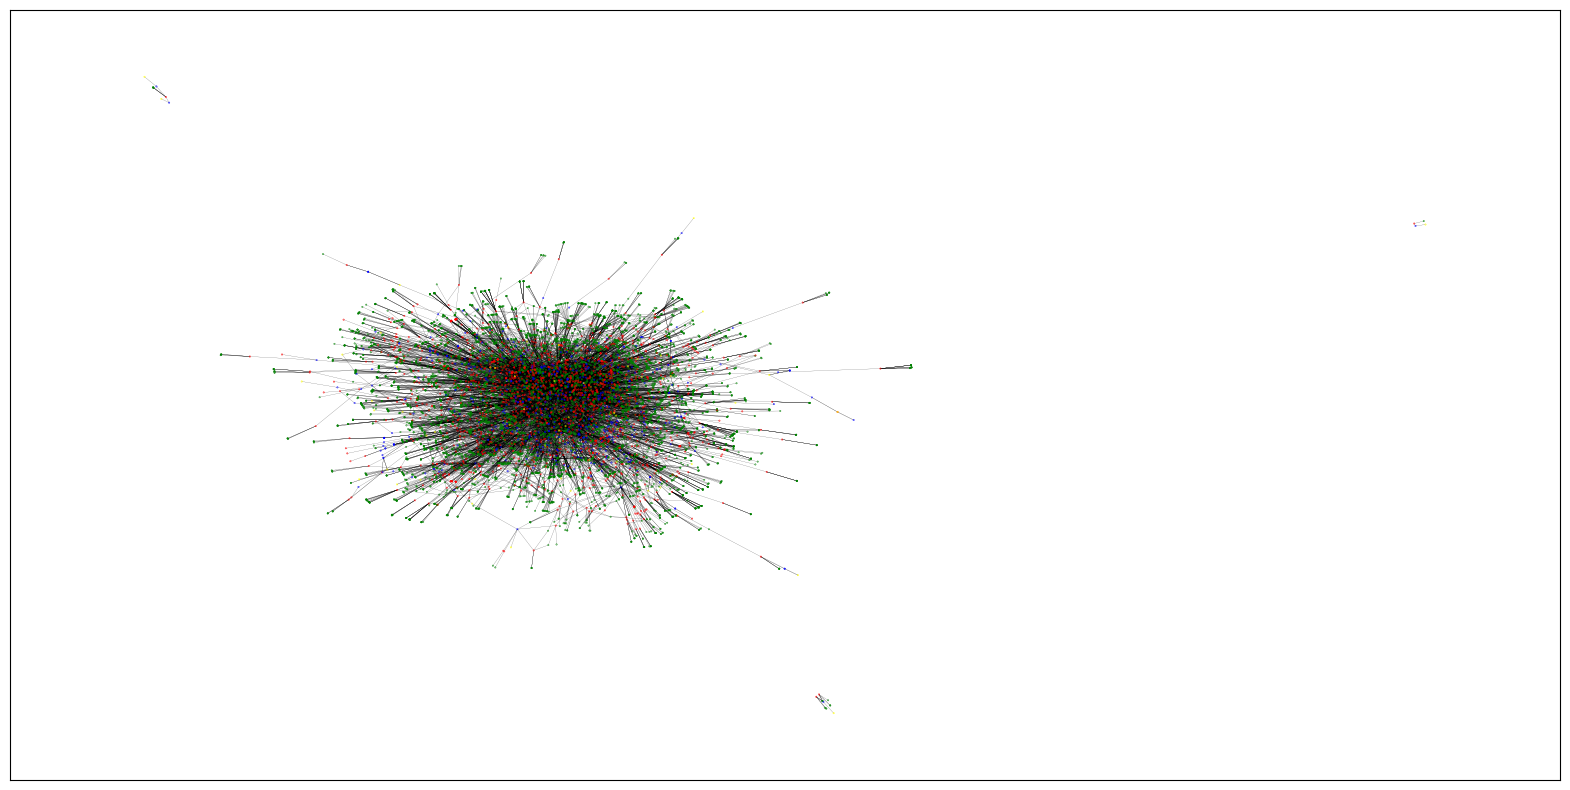

In [15]:
#Diagrama de grafo principal para datos de 2000-2020 (antes 1981 a 2017)
#EL color de los nodos indica su tipo

node_color = []
for x in G_2000_2020.nodes(data = 'tipo'):
    if x[1] == 'articulo':      #Nodos Artículo en rojo
        node_color.append('r')
    elif x[1] == 'autor':       #Nodos Autor en azul
        node_color.append('b')
    elif x[1] == 'keyword':     #Nodos Keyword en verde
        node_color.append('g')
    elif x[1] == 'afiliacion':  #Nodos Afiliacion en amarillo
        node_color.append('yellow')
    else:
        node_color.append('pink')

plt.figure(figsize=(20, 10))
nx.draw_networkx(G_2000_2020, with_labels = False, node_color = node_color, node_size = 0.1, width = 0.1)

In [17]:
#Generación de subgrafo para datos de 2000-2020 (antes 1981 a 2017)

G_sub_2000_2020 = createSubGraph('UNAM_training_2000_2020.csv')
G_sub_2000_2020.number_of_nodes(), G_sub_2000_2020.number_of_edges()

(526, 933)

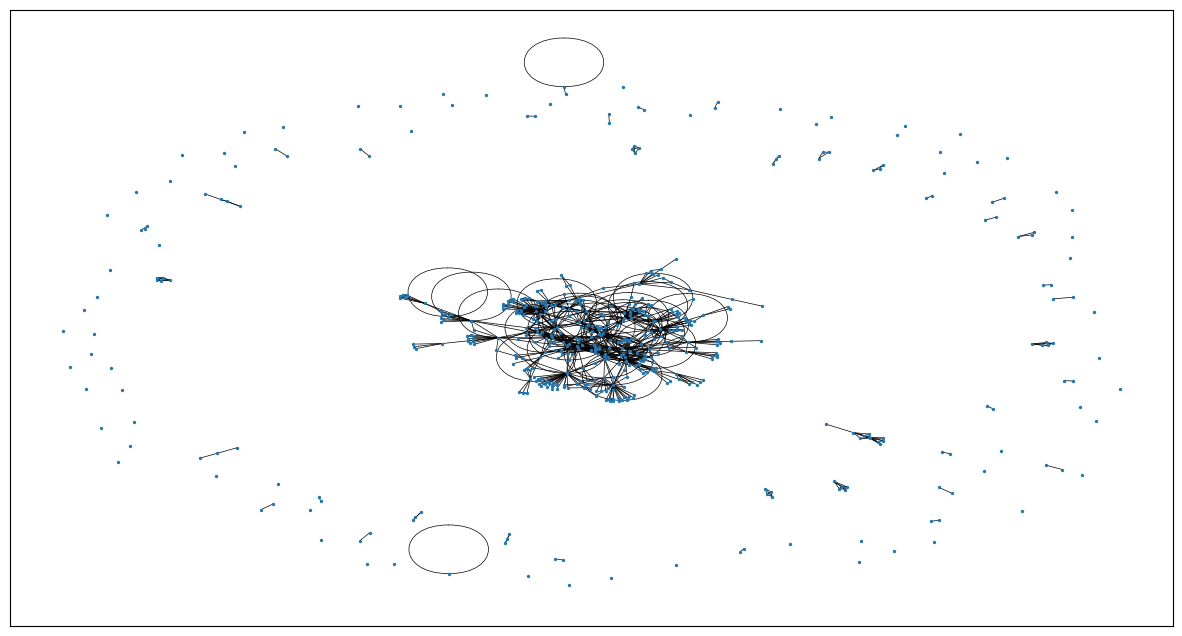

In [18]:
#Diagrama de subgrafo para datos de 2000-2020 (antes 1981 a 2017)

plt.figure(figsize=(15, 8))
nx.draw_networkx(G_sub_2000_2020, with_labels = False, node_size = 2.0, width = 0.5)

In [19]:
# Grafo principal
nx.write_gml(G_2000_2020, 'BD_UNAM_Graph_2000_2020.gml')
# Sub grafo
nx.write_gml(G_sub_2000_2020, 'BD_UNAM_Sub_Graph_2000_2020.gml')

## Generar grafo para datos entre 2021-2022 (antes 2018 y 2021)

In [31]:
#Generación de grafo principal para datos de 2021-2022 (antes 2018 a 2021)

G_2021_2022 = createGraph('UNAM_val_2021_2022.csv')
G_2021_2022.number_of_nodes(), G_2021_2022.number_of_edges()

Longitud lista Keywords: 4483
Longitud lista Keywords únicas: 3327
Total dependencias:  103


(5151, 6752)

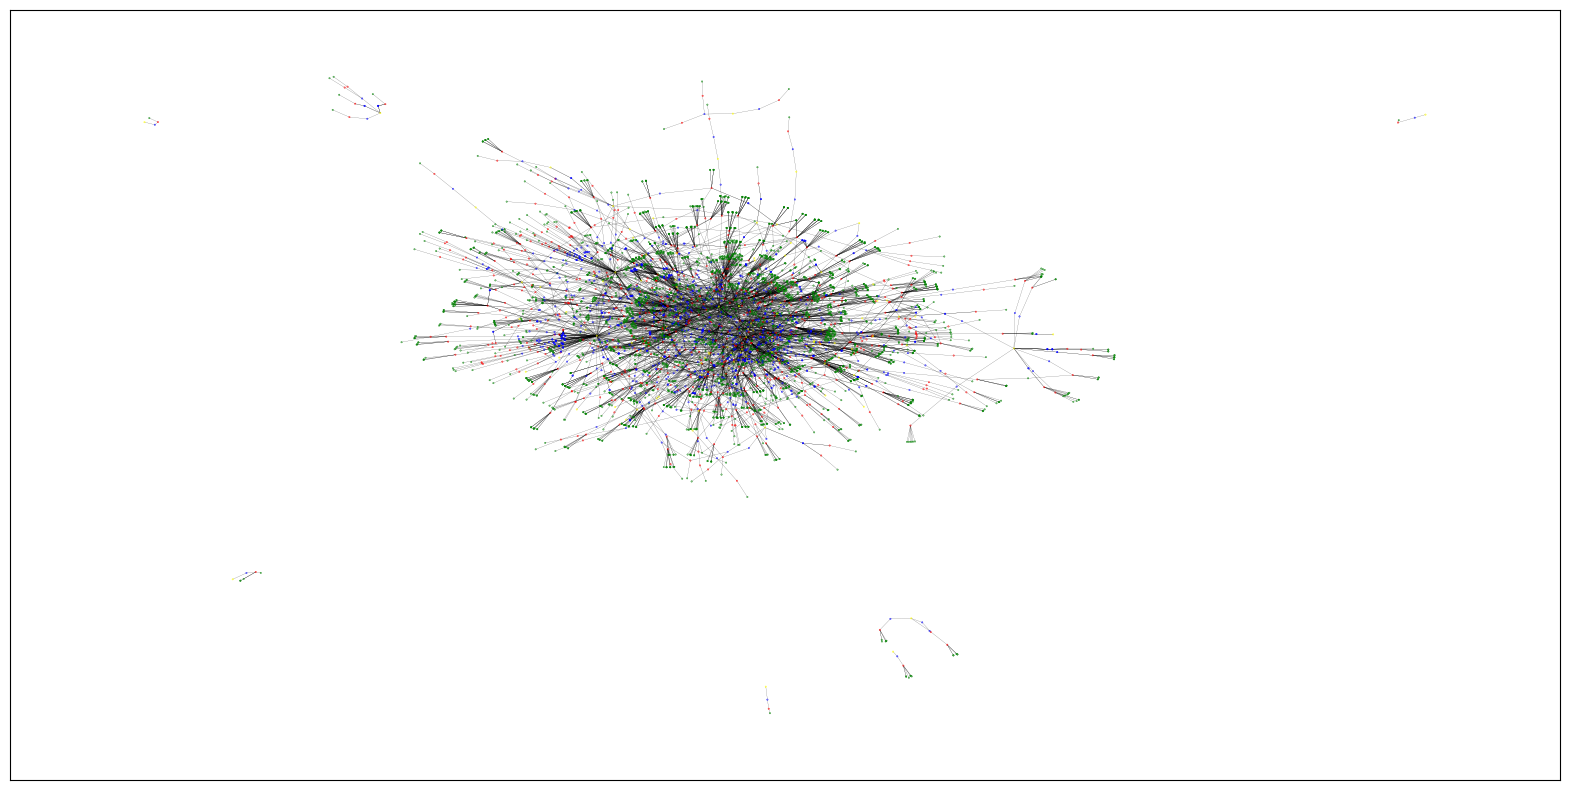

In [32]:
#Diagrama de grafo principal para datos de  2021 a 2022 (antes 2018 a 2021)

node_color = []
for x in G_2021_2022.nodes(data = 'tipo'):
    if x[1] == 'articulo':
        node_color.append('r')        #Nodos Artículo en rojo
    elif x[1] == 'autor':
        node_color.append('b')        #Nodos Autor en azul
    elif x[1] == 'keyword':
        node_color.append('g')        #Nodos Keyword en verde
    elif x[1] == 'afiliacion':
        node_color.append('yellow')   #Nodos Afiliacion en amarillo
    else:
        node_color.append('pink')

plt.figure(figsize=(20, 10))
nx.draw_networkx(G_2021_2022, with_labels = False, node_color = node_color, node_size = 0.1, width = 0.1)

In [22]:
#Generación de subgrafo para datos de 2021 a 2022 (antes 2018 a 2021, 234,432 - ahora 1064,2250)

G_sub_2021_2022 = createSubGraph('UNAM_val_2021_2022.csv')
G_sub_2021_2022.number_of_nodes(), G_sub_2021_2022.number_of_edges()

(1064, 2250)

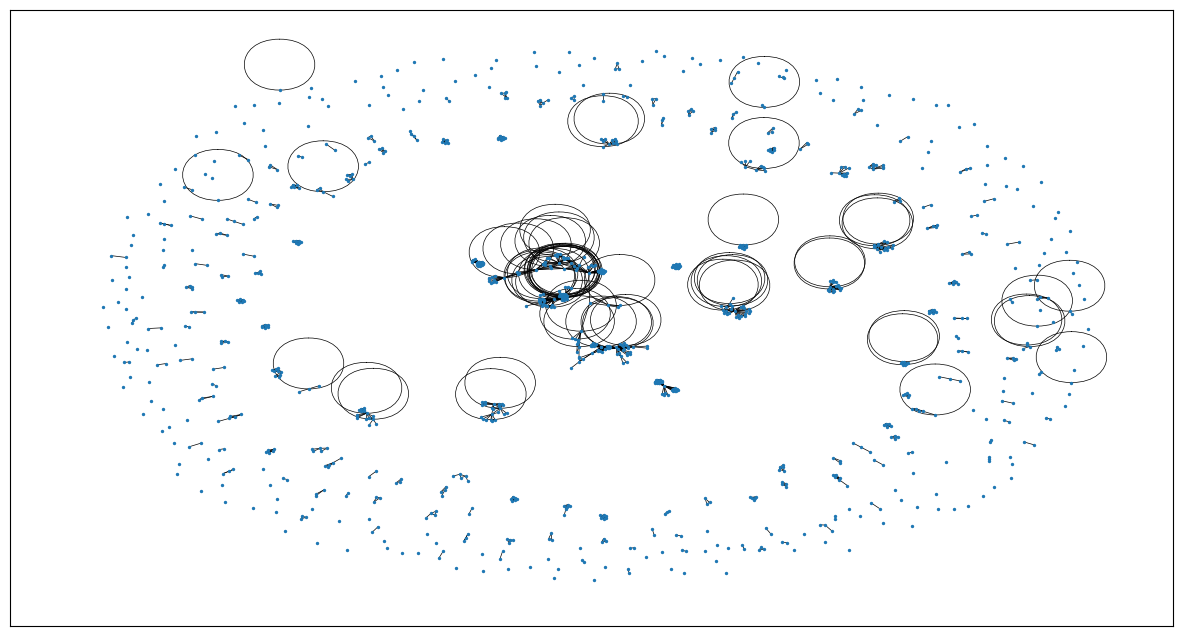

In [33]:
#Diagrama de subgrafo para datos de 2021 a 2022 (antes 2018 a 2021)

plt.figure(figsize=(15, 8))
nx.draw_networkx(G_sub_2021_2022, with_labels = False, node_size = 2.0, width = 0.5)

In [34]:
# Grafo 2021 a 2022 (antes 2018-2021)
nx.write_gml(G_2021_2022, 'BD_UNAM_Graph_2021_2022.gml')
# Sub grafo
nx.write_gml(G_sub_2021_2022, 'BD_UNAM_Sub_Graph_2021_2022.gml')

## Generar grafo para datos entre 2023-2024 (antes inexistente, solo habia dos archivos train y test; ahora train, val y test)

In [35]:
#Generación de grafo principal para datos de 2021-2022 (antes 2018 a 2021)

G_2023_2024 = createGraph('UNAM_test_2023_2024.csv')
G_2023_2024.number_of_nodes(), G_2023_2024.number_of_edges()

Longitud lista Keywords: 2657
Longitud lista Keywords únicas: 2064
Total dependencias:  85


(3207, 4025)

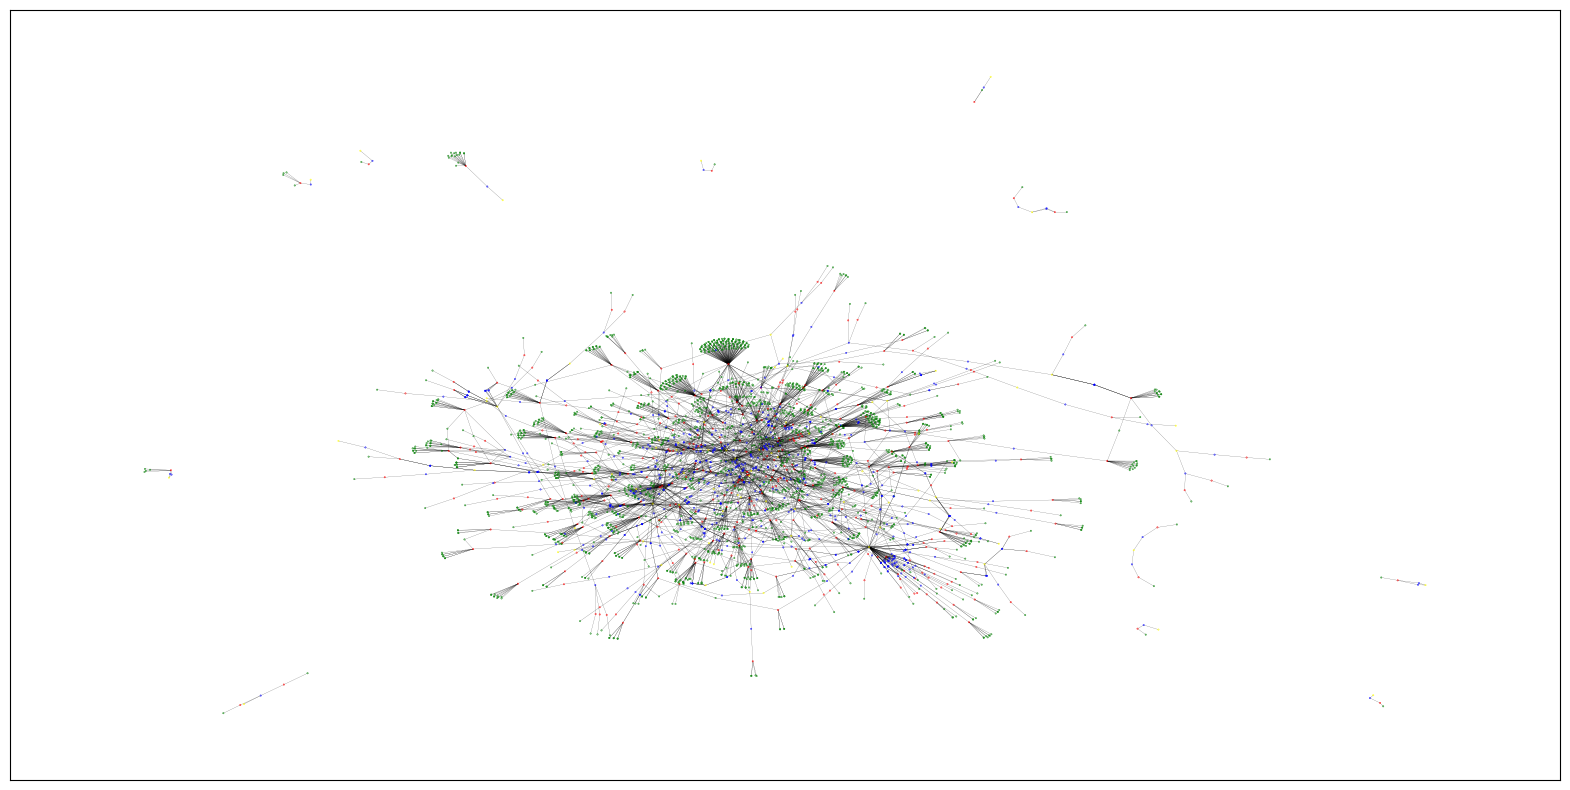

In [36]:
#Diagrama de grafo principal para datos de  2023 a 2025 (antes inexistente)

node_color = []
for x in G_2023_2024.nodes(data = 'tipo'):
    if x[1] == 'articulo':
        node_color.append('r')        #Nodos Artículo en rojo
    elif x[1] == 'autor':
        node_color.append('b')        #Nodos Autor en azul
    elif x[1] == 'keyword':
        node_color.append('g')        #Nodos Keyword en verde
    elif x[1] == 'afiliacion':
        node_color.append('yellow')   #Nodos Afiliacion en amarillo
    else:
        node_color.append('pink')

plt.figure(figsize=(20, 10))
nx.draw_networkx(G_2023_2024, with_labels = False, node_color = node_color, node_size = 0.1, width = 0.1)

In [37]:
#Generación de subgrafo para datos de 2023 a 2024 (662,1179) (antes inexistente)

G_sub_2023_2024 = createSubGraph('UNAM_test_2023_2024.csv')
G_sub_2023_2024.number_of_nodes(), G_sub_2023_2024.number_of_edges()

(662, 1179)

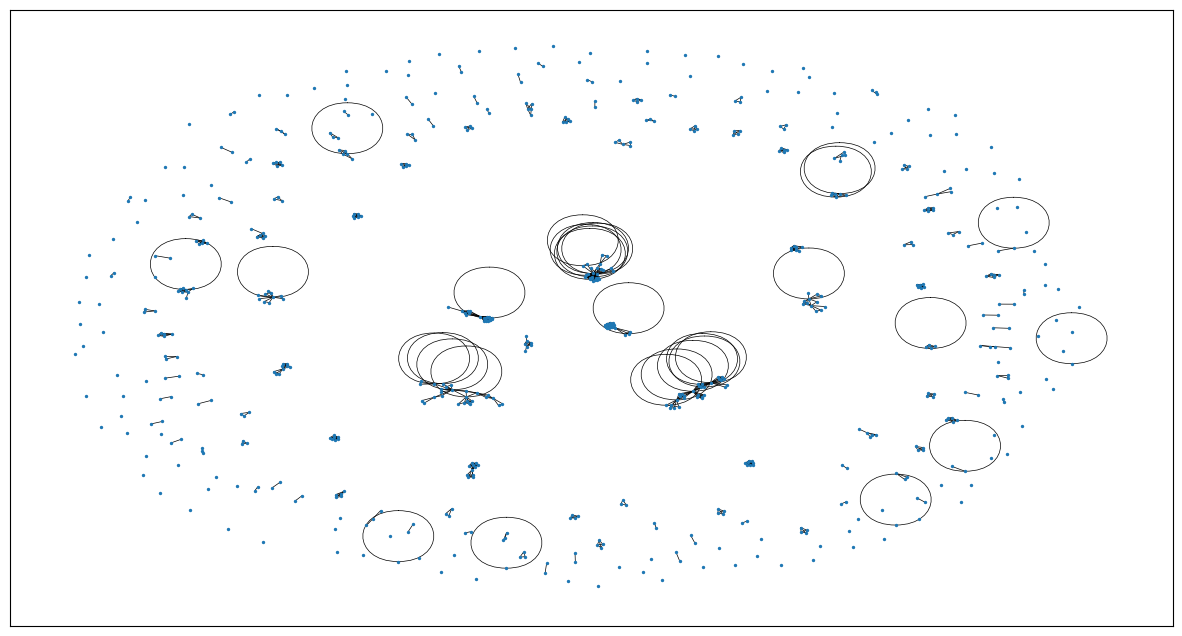

In [38]:
#Diagrama de subgrafo para datos de (antes inexistente)

plt.figure(figsize=(15, 8))
nx.draw_networkx(G_sub_2023_2024, with_labels = False, node_size = 2.0, width = 0.5)

In [39]:
# Grafo principal (antes 2023-2024)
nx.write_gml(G_2023_2024, 'BD_UNAM_Graph_2023_2024.gml')
# Sub grafo
nx.write_gml(G_sub_2023_2024, 'BD_UNAM_Sub_Graph_2023_2024.gml')

In [1]:
# Grafo principal
G_train = nx.read_gml('BD_UNAM_Graph_2000_2020.gml')
# Sub Grafo
G_sub_train = nx.read_gml('BD_UNAM_Sub_Graph_2000_2020.gml')

NameError: name 'nx' is not defined

In [ ]:
G_train.number_of_edges(), G_train.number_of_nodes()